# Privacy-Minimized Product Analytics
\

### Problem
A small product team wants to know one thing: **do users finish the "export report" workflow?** They do not want to collect every click, identity and raw input to answer that. So I build a pipeline that only accepts a fixed list of fields, checks consent on the server side, removes duplicates, and deletes raw data on a schedule.

### What I build
1. 100 fake sessions with rotating test tokens (no real IPs, names, emails or free text)
2. An event contract: allowlist of fields, a forbidden list, a payload size cap, and consent kept outside the event
3. Ingestion that rejects, strips, dedupes and logs the reason for every rejection
4. A funnel in DuckDB with a visible metric definition, late and lost events counted, and small groups hidden
5. Retention and deletion drills, with a clear statement of what is NOT guaranteed
6. Acceptance tests against the known funnel from the data generator

### How to run
Run all cells. All data is made inside the notebook (seed 42). Needs: duckdb, pandas, matplotlib.

In [1]:
!pip install -q duckdb pandas matplotlib

## Step 1: Imports

In [2]:
import json
import random
from datetime import datetime, timedelta

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
con = duckdb.connect()
print("ready")

ready


## Step 2: The event contract (decided BEFORE any data comes in)
- **Question:** what share of sessions that start an export finish it?
- **Events:** `export_start`, `export_success`, `export_fail`. "Abandoned" is not an event. It is a start with no success/fail after 30 minutes
- **Allowed fields:** `event_id`, `session_token`, `event_name`, `event_time`, `app_version`, `step_count`
- **Forbidden fields:** `email`, `ip`, `free_text`, `user_name`, `phone`. If any is present the **whole event is rejected** (policy: reject, do not clean and keep)
- **Unknown fields** that are not forbidden are stripped
- **Size cap:** 300 bytes per payload
- **Consent** comes from a server table and never from the event itself

In [3]:
CONTRACT = {
    "allowed": ["event_id", "session_token", "event_name", "event_time", "app_version", "step_count"],
    "forbidden": ["email", "ip", "free_text", "user_name", "phone"],
    "event_names": ["export_start", "export_success", "export_fail"],
    "max_bytes": 300,
    "abandon_minutes": 30,
}
print(CONTRACT)

{'allowed': ['event_id', 'session_token', 'event_name', 'event_time', 'app_version', 'step_count'], 'forbidden': ['email', 'ip', 'free_text', 'user_name', 'phone'], 'event_names': ['export_start', 'export_success', 'export_fail'], 'max_bytes': 300, 'abandon_minutes': 30}


## Step 3: Make 100 fake sessions with a known answer
Ground truth (made by the generator, so I can check my numbers later):
- 98 sessions gave consent, 2 did not
- Of the 98: **60 success, 14 fail, 22 abandoned, 2 still in progress** at the data cut-off
- Of the 60 successes: **5 arrive late** (2 to 3 days after they happened, after the cut-off) and **4 are lost** (never delivered)
- Messy delivery: 7 events are delivered twice, 3 extra payloads contain forbidden fields, 1 payload is too large, 1 has an unknown extra field

In [4]:
BASE = datetime(2026, 9, 1)
CUTOFF = datetime(2026, 9, 8)
versions = ["1.0", "1.1", "2.0"]


def token():
    return "t-" + "".join(random.choice("0123456789abcdef") for _ in range(8))


sessions = []
plan = ["success"] * 60 + ["fail"] * 14 + ["abandoned"] * 22
random.shuffle(plan)
late_ids = set(random.sample(range(60), 5))
lost_ids = set(random.sample([i for i in range(60) if i not in late_ids], 4))

n_success = 0
for i, outcome in enumerate(plan):
    day = random.randint(0, 6)
    start = BASE + timedelta(days=day, hours=random.randint(8, 20), minutes=random.randint(0, 59))
    s = {"token": token(), "outcome": outcome, "start": start, "version": random.choice(versions[:2]) if i % 9 != 0 else "2.0", "consent": True, "late": False, "lost": False}
    if outcome == "success":
        s["late"] = n_success in late_ids
        s["lost"] = n_success in lost_ids
        n_success += 1
    if i in (3, 40, 77):
        s["version"] = "2.0-beta"
    sessions.append(s)

# 2 sessions that started 10 minutes before the cut-off (still in progress)
for _ in range(2):
    sessions.append({"token": token(), "outcome": "in_progress", "start": CUTOFF - timedelta(minutes=10), "version": "1.1", "consent": True, "late": False, "lost": False})
# 2 sessions without consent
for _ in range(2):
    sessions.append({"token": token(), "outcome": "success", "start": BASE + timedelta(days=2, hours=10), "version": "1.0", "consent": False, "late": False, "lost": False})

print("sessions:", len(sessions))
print(pd.Series([s["outcome"] for s in sessions]).value_counts().to_dict())

sessions: 100
{'success': 62, 'abandoned': 22, 'fail': 14, 'in_progress': 2}


In [5]:
payloads = []   # what the client sends: (payload dict, arrival_time)
eid = 0


def new_eid():
    global eid
    eid += 1
    return "e" + str(eid).zfill(4)


for s in sessions:
    start_ev = {"event_id": new_eid(), "session_token": s["token"], "event_name": "export_start",
                "event_time": s["start"].isoformat(), "app_version": s["version"], "step_count": 1}
    payloads.append((start_ev, s["start"] + timedelta(seconds=random.randint(1, 30))))

    if s["outcome"] in ("success", "fail"):
        name = "export_success" if s["outcome"] == "success" else "export_fail"
        t = s["start"] + timedelta(minutes=random.randint(1, 9))
        ev = {"event_id": new_eid(), "session_token": s["token"], "event_name": name,
              "event_time": t.isoformat(), "app_version": s["version"], "step_count": 3}
        if s["lost"]:
            continue
        arrive = t + timedelta(seconds=random.randint(1, 30))
        if s["late"]:
            arrive = CUTOFF + timedelta(days=random.randint(1, 3), hours=random.randint(1, 5))
        payloads.append((ev, arrive))

# repeated deliveries (same event_id sent again)
dups = random.sample(payloads, 7)
for ev, arrive in dups:
    payloads.append((dict(ev), arrive + timedelta(minutes=1)))

# forbidden payloads: new event ids, from sessions that exist
forbid_examples = [("email", "someone@example.com"), ("free_text", "my report is about salaries"), ("ip", "10.1.2.3")]
for field, value in forbid_examples:
    s = random.choice([x for x in sessions if x["consent"] and x["outcome"] == "success" and not x["lost"]])
    ev = {"event_id": new_eid(), "session_token": s["token"], "event_name": "export_start",
          "event_time": s["start"].isoformat(), "app_version": s["version"], "step_count": 1, field: value}
    payloads.append((ev, s["start"] + timedelta(minutes=2)))

# too large payload and unknown field payload
s = random.choice([x for x in sessions if x["consent"] and x["outcome"] == "fail"])
payloads.append(({"event_id": new_eid(), "session_token": s["token"], "event_name": "export_start", "event_time": s["start"].isoformat(),
                  "app_version": "x" * 400, "step_count": 1}, s["start"] + timedelta(minutes=3)))
payloads.append(({"event_id": new_eid(), "session_token": s["token"], "event_name": "export_fail", "event_time": (s["start"] + timedelta(minutes=5)).isoformat(),
                  "app_version": s["version"], "step_count": 3, "debug_note": "retry"}, s["start"] + timedelta(minutes=5, seconds=3)))
# NOTE: the fail event above is a second fail for a failed session, it tests the unknown-field strip

payloads.sort(key=lambda x: x[1])
print("payloads delivered:", len(payloads))
print(payloads[0])

payloads delivered: 184
({'event_id': 'e0038', 'session_token': 't-485ed032', 'event_name': 'export_start', 'event_time': '2026-09-01T08:21:00', 'app_version': '1.0', 'step_count': 1}, datetime.datetime(2026, 9, 1, 8, 21, 9))


## Step 4: Server tables and ingestion
`consent` is a server table (token -> scope). `events` stores only allowed fields plus `arrival_time` that the **server** sets. `rejected` keeps only the event id and the reason, not the content.

In [6]:
con.execute("create table consent (session_token varchar primary key, scope varchar)")
con.execute('''create table events (event_id varchar primary key, session_token varchar, event_name varchar,
               event_time timestamp, arrival_time timestamp, app_version varchar, step_count int)''')
con.execute("create table rejected (event_id varchar, reason varchar)")

for s in sessions:
    con.execute("insert into consent values (?, ?)", [s["token"], "analytics" if s["consent"] else "none"])

counts = {"accepted": 0, "duplicate": 0, "rejected": 0, "stripped_fields": 0}


def ingest(payload, arrival):
    eid_ = str(payload.get("event_id", "missing"))

    for bad in CONTRACT["forbidden"]:
        if bad in payload:
            con.execute("insert into rejected values (?, ?)", [eid_, "forbidden field: " + bad])
            counts["rejected"] += 1
            return
    if len(json.dumps(payload)) > CONTRACT["max_bytes"]:
        con.execute("insert into rejected values (?, ?)", [eid_, "payload too large"])
        counts["rejected"] += 1
        return
    if payload.get("event_name") not in CONTRACT["event_names"]:
        con.execute("insert into rejected values (?, ?)", [eid_, "unknown event name"])
        counts["rejected"] += 1
        return
    scope = con.execute("select scope from consent where session_token = ?", [payload.get("session_token")]).fetchone()
    if scope is None or scope[0] != "analytics":
        con.execute("insert into rejected values (?, ?)", [eid_, "no consent"])
        counts["rejected"] += 1
        return

    clean = {}
    for k, v in payload.items():
        if k in CONTRACT["allowed"]:
            clean[k] = v
        else:
            counts["stripped_fields"] += 1

    exists = con.execute("select count(*) from events where event_id = ?", [clean["event_id"]]).fetchone()[0]
    if exists > 0:
        counts["duplicate"] += 1
        return
    con.execute("insert into events values (?,?,?,?,?,?,?)", [clean["event_id"], clean["session_token"], clean["event_name"],
                clean["event_time"], arrival, clean["app_version"], clean.get("step_count")])
    counts["accepted"] += 1


for p, a in payloads:
    ingest(p, a)

print(counts)
print()
print(con.execute("select reason, count(*) as n from rejected group by reason order by n desc").df())

{'accepted': 169, 'duplicate': 7, 'rejected': 8, 'stripped_fields': 1}

                       reason  n
0                  no consent  4
1  forbidden field: free_text  1
2         forbidden field: ip  1
3           payload too large  1
4      forbidden field: email  1


## Step 5: The funnel (metric definition is printed with the result)
**Definition:** among consented sessions, `completion rate` = sessions with `export_success` / sessions that started AND are older than 30 minutes at the data cut-off. Events are deduplicated by `event_id`. Sessions that started less than 30 minutes before the cut-off are `in_progress` and are not counted in the rate.

I run the same query at two moments: when the data was cut (day 8, late events missing) and after everything arrived.

In [7]:
METRIC_DEF = ("completion rate = export_success sessions / sessions started at least 30 min before cut-off "
              "(consented only, deduplicated by event_id, in-progress sessions excluded)")


def funnel(as_of, cutoff):
    q = '''
    with starts as (
        select session_token, min(event_time) as t0 from events
        where event_name = 'export_start' and arrival_time <= ? group by 1
    ),
    ends as (
        select session_token,
               max(case when event_name = 'export_success' then 1 else 0 end) as ok,
               max(case when event_name = 'export_fail' then 1 else 0 end) as bad
        from events where arrival_time <= ? and event_name in ('export_success', 'export_fail') group by 1
    ),
    joined as (
        select s.session_token, s.t0, coalesce(e.ok, 0) as ok, coalesce(e.bad, 0) as bad
        from starts s left join ends e using (session_token)
    )
    select
        count(*) as started,
        sum(case when ok = 1 then 1 else 0 end) as success,
        sum(case when ok = 0 and bad = 1 then 1 else 0 end) as fail,
        sum(case when ok = 0 and bad = 0 and t0 <= ? - interval 30 minute then 1 else 0 end) as abandoned,
        sum(case when ok = 0 and bad = 0 and t0 > ? - interval 30 minute then 1 else 0 end) as in_progress
    from joined
    '''
    r = con.execute(q, [as_of, as_of, cutoff, cutoff]).fetchone()
    out = {"started": r[0], "success": r[1], "fail": r[2], "abandoned": r[3], "in_progress": r[4]}
    denom = out["started"] - out["in_progress"]
    out["completion_rate"] = round(out["success"] / denom, 3) if denom > 0 else None
    return out


at_cut = funnel(CUTOFF, CUTOFF)
final = funnel(CUTOFF + timedelta(days=10), CUTOFF)
truth = {"started": 98, "success": 60, "fail": 14, "abandoned": 22, "in_progress": 2, "completion_rate": round(60 / 96, 3)}
cmp_df = pd.DataFrame([truth, at_cut, final], index=["truth (generator)", "as of cut-off", "after late events"])
print(METRIC_DEF)
print()
print(cmp_df.to_string())

completion rate = export_success sessions / sessions started at least 30 min before cut-off (consented only, deduplicated by event_id, in-progress sessions excluded)

                   started  success  fail  abandoned  in_progress  completion_rate
truth (generator)       98       60    14         22            2            0.625
as of cut-off           98       51    14         31            2            0.531
after late events       98       56    14         26            2            0.583


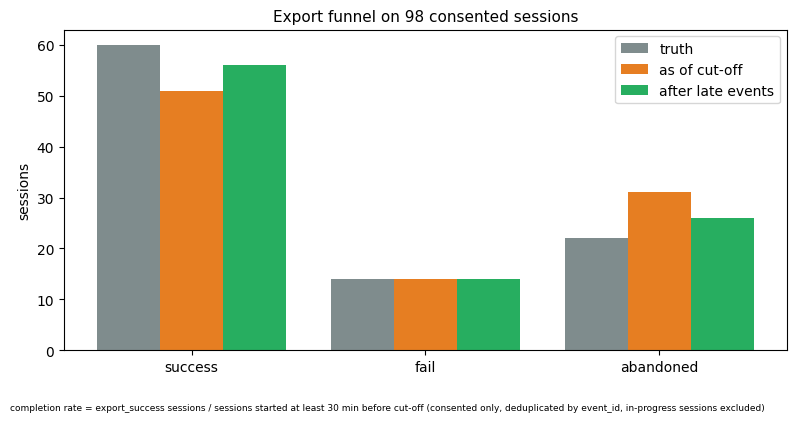

late events effect: success 51 -> 56
lost events (never delivered, known from generator): 4 -> final success 56 vs truth 60


In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
labels = ["success", "fail", "abandoned"]
x = range(len(labels))
w = 0.27
ax.bar([i - w for i in x], [truth[l] for l in labels], w, label="truth", color="#7f8c8d")
ax.bar(list(x), [at_cut[l] for l in labels], w, label="as of cut-off", color="#e67e22")
ax.bar([i + w for i in x], [final[l] for l in labels], w, label="after late events", color="#27ae60")
ax.set_xticks(list(x))
ax.set_xticklabels(labels)
ax.set_ylabel("sessions")
ax.set_title("Export funnel on 98 consented sessions", fontsize=11)
ax.legend()
fig.text(0.01, 0.01, METRIC_DEF, fontsize=6.5, wrap=True)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig("export_funnel.png")
plt.show()
print("late events effect: success", at_cut["success"], "->", final["success"])
print("lost events (never delivered, known from generator): 4 -> final success", final["success"], "vs truth", truth["success"])

## Step 6: Hide small groups
Breakdown by app version (a tiny `2.0-beta` group exists on purpose). Any group with fewer than 5 sessions is shown as `<5`, so that a tiny group can not point at one person.

In [9]:
MIN_GROUP = 5
by_ver = con.execute('''
    select s.app_version, count(distinct s.session_token) as sessions,
           count(distinct case when e.event_name = 'export_success' then e.session_token end) as success
    from events s left join events e on s.session_token = e.session_token
    where s.event_name = 'export_start'
    group by 1 order by 1
''').df()


def show_safe(df):
    out = df.copy()
    out["sessions"] = out["sessions"].astype(object)
    out["success"] = out["success"].astype(object)
    for i in out.index:
        if out.loc[i, "sessions"] < MIN_GROUP:
            out.loc[i, "sessions"] = "<5"
            out.loc[i, "success"] = "hidden"
    return out


print("raw (not shown to anyone):")
print(by_ver)
print()
print("what the dashboard shows:")
print(show_safe(by_ver))

raw (not shown to anyone):
  app_version  sessions  success
0         1.0        37       26
1         1.1        47       22
2         2.0        11        6
3    2.0-beta         3        2

what the dashboard shows:
  app_version sessions success
0         1.0       37      26
1         1.1       47      22
2         2.0       11       6
3    2.0-beta       <5  hidden


## Step 7: Retention and deletion drill
- Today is 2026-09-20 and raw events are kept for 14 days, so anything with `event_time` before 2026-09-06 expires
- Before deleting raw data I save a **daily aggregate** (counts only, no tokens)
- A deletion request for one `session_token` removes that session's raw events
- What is NOT guaranteed: aggregates that were already saved still include that session's count. Deleting raw rows does not make every derived risk disappear

In [10]:
con.execute("create table daily_agg as select cast(event_time as date) as day, event_name, count(*) as n_events, count(distinct session_token) as n_sessions from events group by 1, 2")
agg_before = con.execute("select sum(n_events) from daily_agg").fetchone()[0]
raw_before = con.execute("select count(*) from events").fetchone()[0]

TODAY = datetime(2026, 9, 20)
RETENTION_DAYS = 14
limit = TODAY - timedelta(days=RETENTION_DAYS)
con.execute("delete from events where event_time < ?", [limit])
raw_after = con.execute("select count(*) from events").fetchone()[0]
print("raw events before:", raw_before, "| after retention delete:", raw_after, "| oldest remaining event:", con.execute("select min(event_time) from events").fetchone()[0])
print("daily_agg kept:", con.execute("select count(*) from daily_agg").fetchone()[0], "rows | events counted in it:", agg_before)

# deletion request for one user token that still has raw data
tok = con.execute("select session_token from events limit 1").fetchone()[0]
n_tok = con.execute("select count(*) from events where session_token = ?", [tok]).fetchone()[0]
con.execute("delete from events where session_token = ?", [tok])
left = con.execute("select count(*) from events where session_token = ?", [tok]).fetchone()[0]
print("deletion request for", tok, "-> raw rows removed:", n_tok, "| left:", left)
print("daily_agg still has the old totals:", con.execute("select sum(n_events) from daily_agg").fetchone()[0] == agg_before)

raw events before: 169 | after retention delete: 55 | oldest remaining event: 2026-09-06 08:03:00
daily_agg kept: 21 rows | events counted in it: 169
deletion request for t-fcd3fe22 -> raw rows removed: 2 | left: 0
daily_agg still has the old totals: True


## Step 8: Acceptance tests

In [11]:
# test 1: forbidden fields are rejected with a reason, unknown fields are stripped, oversize is rejected
rej = con.execute("select reason, count(*) from rejected group by reason").fetchall()
rej_dict = dict(rej)
ok1 = (rej_dict.get("forbidden field: email", 0) == 1 and rej_dict.get("forbidden field: free_text", 0) == 1
       and rej_dict.get("forbidden field: ip", 0) == 1 and rej_dict.get("payload too large", 0) == 1)
cols = [r[0] for r in con.execute("describe events").fetchall()]
ok1 = ok1 and ("debug_note" not in cols) and counts["stripped_fields"] >= 1
print("TEST 1 forbidden/oversize rejected, unknown field stripped (stripped count", counts["stripped_fields"], "):", "PASS" if ok1 else "FAIL")

# test 2: repeated delivery does not inflate the denominator
print("TEST 2 duplicates ignored:", counts["duplicate"], "| started sessions:", final["started"], "(truth 98) ->", "PASS" if final["started"] == 98 and counts["duplicate"] == 7 else "FAIL")

# test 3: no-consent sessions never reach the events table
no_cons = con.execute("select count(*) from events e join consent c using (session_token) where c.scope = 'none'").fetchone()[0]
print("TEST 3 events from no-consent sessions:", no_cons, "->", "PASS" if no_cons == 0 else "FAIL")

# test 4: funnel matches the generator once lost events are accounted for
exp_success = 60 - 4
print("TEST 4 success after all arrivals:", final["success"], "| expected 60 - 4 lost =", exp_success, "->", "PASS" if final["success"] == exp_success else "FAIL")

# test 5: retention and deletion
print("TEST 5 old raw rows removed:", raw_before - raw_after > 0, "| token rows left:", left, "->", "PASS" if raw_before - raw_after > 0 and left == 0 else "FAIL")

TEST 1 forbidden/oversize rejected, unknown field stripped (stripped count 1 ): PASS
TEST 2 duplicates ignored: 7 | started sessions: 98 (truth 98) -> PASS
TEST 3 events from no-consent sessions: 0 -> PASS
TEST 4 success after all arrivals: 56 | expected 60 - 4 lost = 56 -> PASS
TEST 5 old raw rows removed: True | token rows left: 0 -> PASS


---
**Built by Akshat Kesharwani**  |  Portfolio: https://akshatkesharwani-info.github.io/  |  GitHub: https://github.com/akshatkesharwani-info
